# 04. 학습곡선 읽기와 최적 epoch 찾기


## 0. 작업 전 준비사항
이번 실습은 Matplotlib과 Python 리스트를 사용해 제공된 손실값을 분석하고 그래프를 그립니다.

Matplotlib이 설치된 Python 커널을 선택하고 **Run All(모두 실행)**로 위에서 아래로 실행하세요. 커널을 재시작하면 import와 변수가 초기화되므로 첫 코드 셀부터 다시 실행합니다.


## 1. 실습 목적과 데이터
학습 손실과 검증 손실의 흐름을 비교하고, 검증 손실이 가장 작은 epoch를 찾습니다.

**아래 손실값은 곡선 해석용으로 제공된 설명용 데이터입니다. 실제 모델을 학습해서 얻은 결과가 아닙니다.** 이 실습에서는 모델, Optimizer, 역전파를 사용하지 않습니다. 07번 실습에서는 직접 학습한 결과를 기록합니다.

- `train_losses`: 학습 데이터에 대한 손실 20개
- `valid_losses`: 검증 데이터에 대한 손실 20개
- 각 리스트의 첫 항목은 1 epoch, 마지막 항목은 20 epoch에 대응합니다.

노트북에서는 `__file__` 대신 현재 작업 폴더를 기준으로 이미지 저장 경로를 정합니다. 저장소 루트, `01_기본필수`, `docs`에서 실행할 수 있습니다.


In [1]:
from pathlib import Path
import matplotlib
matplotlib.use("Agg")  # PNG로 저장한 뒤 노트북에 표시합니다.
import matplotlib.pyplot as plt

# 아래 20개 값은 학습곡선 읽기용으로 제공한 설명용 값입니다.
# 실제 모델 실행 결과라고 보고하지 않습니다. 07번은 직접 학습한 곡선을 그립니다.
train_losses = [0.90,0.76,0.65,0.56,0.49,0.43,0.38,0.33,0.29,0.25,
                0.22,0.20,0.18,0.16,0.14,0.13,0.12,0.11,0.10,0.09]
valid_losses = [0.94,0.81,0.71,0.61,0.53,0.47,0.42,0.38,0.35,0.33,
                0.32,0.33,0.35,0.37,0.40,0.43,0.46,0.48,0.50,0.52]


## 2. 최소 손실값의 위치로 epoch 구하기
Python의 `min()`과 리스트의 `index()`를 사용해 최적 epoch를 구합니다.

```python
best_epoch = valid_losses.index(min(valid_losses)) + 1
```

| 표현 | 의미 | 이번 결과 |
| --- | --- | --- |
| `min(valid_losses)` | 가장 작은 손실값 | `0.32` |
| `valid_losses.index(min(valid_losses))` | 최소값의 위치 (0부터 시작) | `10` |
| `valid_losses.index(min(valid_losses)) + 1` | epoch (1부터 시작) | `11` |

최소값 자체에 1을 더하는 것이 아니라, 최소값이 있는 위치를 찾아 1을 더합니다. 최소값이 여러 번 등장하면 `index()`는 처음 등장한 위치를 반환합니다.


In [2]:
# valid_losses에서 가장 작은 값의 위치를 구하고 1을 더해 best_epoch에 넣으세요.
# 리스트 위치는 0부터, 여기서 출력할 epoch는 1부터 시작합니다.
# >>> B05
# TODO B05: 위 요구사항에 맞게 이 블록만 완성합니다.
best_epoch = valid_losses.index(min(valid_losses)) + 1
# <<< B05
print("best epoch:", best_epoch, "최소 valid loss:", min(valid_losses))
plt.figure(figsize=(8, 5))
plt.plot(range(1, 21), train_losses, label="train")
plt.plot(range(1, 21), valid_losses, label="valid")
plt.axvline(best_epoch, linestyle="--", label="best epoch")
plt.xlabel("Epoch")
plt.ylabel("Cross entropy loss")
plt.legend()
plt.tight_layout()
candidates = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd() / "20261030" / "01_기본필수",
]
base = next((path for path in candidates if (path / "04_curves.py").is_file()), None)
if base is None:
    raise FileNotFoundError("저장소 루트, 01_기본필수 또는 docs 폴더에서 실행하세요.")
output_path = base / "practice04_curves.png"
plt.savefig(output_path, dpi=150)
plt.close()
print("생성: practice04_curves.png")


best epoch: 11 최소 valid loss: 0.32
생성: practice04_curves.png


## 3. 학습곡선 확인
가로축은 epoch, 세로축은 교차 엔트로피 손실입니다. `train`과 `valid` 곡선을 비교하고, 점선으로 표시된 검증 손실 최소 지점을 확인합니다.


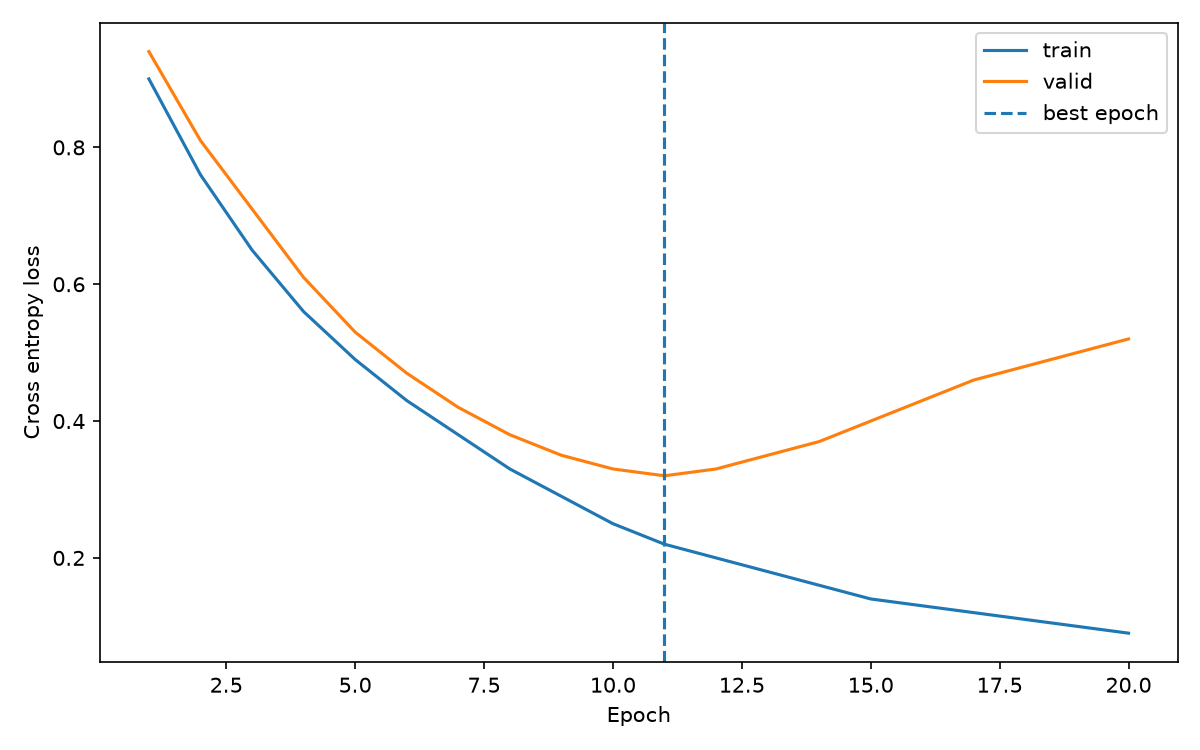

In [3]:
from IPython.display import Image, display

display(Image(filename=str(output_path)))


## 4. 결과 해석 및 추가 실험
실행 결과는 **best epoch: 11, 최소 valid loss: 0.32**입니다. 마지막 20 epoch의 검증 손실은 `0.52`로 최소값보다 `0.20` 큽니다.

### 완료 질문에 대한 설명
**11회 이후 train과 valid가 다르게 움직이는 이유는?**

제공된 곡선에서는 11 epoch 이후 학습 손실은 계속 감소하지만 검증 손실은 증가합니다. 실제 학습에서 이런 흐름은 학습 데이터에 점점 더 맞추는 동안 새로운 데이터에 대한 일반화 성능이 나빠지는 **과적합의 신호**로 해석할 수 있습니다. 이번 값은 설명용이므로 실제 모델의 과적합을 실험으로 입증한 결과는 아닙니다.

가장 오래 학습한 모델이나 학습 손실이 가장 작은 모델이 검증 성능도 가장 좋은 것은 아닙니다. 이 데이터에서는 검증 손실을 기준으로 11 epoch를 선택할 수 있습니다. 정확도는 측정하지 않았으므로 정확도 변화까지 단정하지 않습니다.

### 직접 확인해 볼 내용
- `valid_losses[-1]`과 `min(valid_losses)`를 비교해 마지막 epoch와 최적 epoch의 차이를 확인합니다.
- 최소값이 두 번 등장하는 예시를 만들어 `list.index`이 첫 위치를 고르는지 확인합니다.
- 실제 학습에서는 같은 epoch 종료 후 같은 평가 모드에서 train·valid 손실을 측정해 비교합니다.
- 검증 결과로 epoch를 선택하고, test 데이터는 설정 선택이 끝난 후 최종 평가에 사용합니다.

### 자주 하는 실수 점검
- 최소값을 구하는 `min`과 위치를 구하는 `index`을 구분했는가?
- 인덱스가 0부터 시작하므로 epoch 표시를 위해 1을 더했는가?
- 설명용 손실값을 실제 모델 실행 결과로 보고하지 않았는가?
- 점선의 위치를 찾았다는 이유로 최적 모델의 가중치도 저장했다고 생각하지 않았는가? 이 코드는 모델 저장·복원을 수행하지 않습니다.

검증 손실을 관찰해 학습을 중단하는 Early Stopping이나 최적 가중치를 저장하는 방법으로 확장할 수 있지만, 이번 코드는 제공된 20개 값을 모두 확인한 뒤 최소 지점을 찾는 실습입니다.
